# Assignment 8 — The Discipline of Forgetting

**COMP 3200 — Deep Learning**

This notebook demonstrates overfitting using the MNIST handwritten digit dataset. We first train a neural network on a small dataset to observe overfitting, then apply early stopping and dropout to improve generalization. Finally, we implement mini-batch gradient descent to improve training speed while maintaining similar validation accuracy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

from data import load_mnist, one_hot

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = load_mnist()

X_train = X_train_full[:1000]
Y_train = one_hot(y_train_full[:1000])

X_val = X_train_full[1000:2000]
Y_val = one_hot(y_train_full[1000:2000])

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)

Training images: (1000, 784)
Validation images: (1000, 784)


## Part 1 — Memorize on Purpose
**Robert**

In [3]:
from part1_memorize import train, evaluate

W1_part1, W2_part1, train_hist, val_hist = train(
    X_train, Y_train, X_val, Y_val
)

iter   0 train_acc=0.527 val_acc=0.656
iter   1 train_acc=0.749 val_acc=0.718
iter   2 train_acc=0.802 val_acc=0.764
iter   3 train_acc=0.851 val_acc=0.804
iter   4 train_acc=0.883 val_acc=0.818
iter   5 train_acc=0.898 val_acc=0.837
iter   6 train_acc=0.908 val_acc=0.851
iter   7 train_acc=0.917 val_acc=0.854
iter   8 train_acc=0.923 val_acc=0.859
iter   9 train_acc=0.929 val_acc=0.860
iter  10 train_acc=0.940 val_acc=0.863
iter  11 train_acc=0.944 val_acc=0.861
iter  12 train_acc=0.952 val_acc=0.866
iter  13 train_acc=0.957 val_acc=0.869
iter  14 train_acc=0.957 val_acc=0.868
iter  15 train_acc=0.959 val_acc=0.869
iter  16 train_acc=0.960 val_acc=0.867
iter  17 train_acc=0.963 val_acc=0.867
iter  18 train_acc=0.964 val_acc=0.867
iter  19 train_acc=0.967 val_acc=0.870
iter  20 train_acc=0.972 val_acc=0.872
iter  21 train_acc=0.977 val_acc=0.870
iter  22 train_acc=0.978 val_acc=0.870
iter  23 train_acc=0.980 val_acc=0.872
iter  24 train_acc=0.980 val_acc=0.872
iter  25 train_acc=0.981 

In [4]:
best_iter1 = np.argmax(val_hist)

print(f"Final training accuracy: {train_hist[-1] * 100:.2f}%")
print(f"Final validation accuracy: {val_hist[-1] * 100:.2f}%")
print(f"Best validation accuracy: {val_hist[best_iter1] * 100:.2f}%")
print(f"Best validation iteration: {best_iter1}")

Final training accuracy: 99.90%
Final validation accuracy: 82.80%
Best validation accuracy: 87.30%
Best validation iteration: 27


In [5]:
plt.figure(figsize = (8, 5))
plt.plot(train_hist, label="Training Accuracy")
plt.plot(val_hist, label="Validation Accuracy)")
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("curves_part1.png")
plt.close()

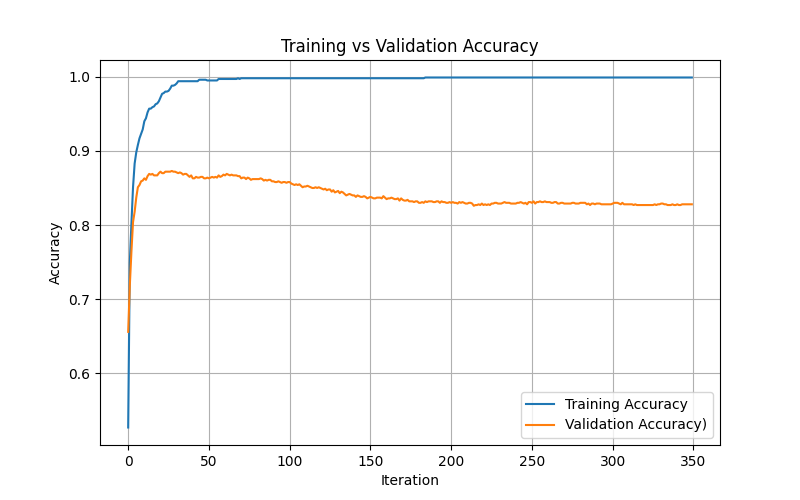

In [6]:
from IPython.display import Image, display

display(Image(filename="curves_part1.png"))

### Part 1 Results

Over 350 training iterations, the network achieved 99.9% training accuracy yet only 82.8% validation accuracy. Validation peaked at 87.3% at iteration 27 before declining through the rest of training. This shows that overfitting occurred because its training showed continuous improvement while not actually improving ability to classify unseen images. This shows that stopping training earlier could make a model that generalizes better.

## Part 2 — Early Stopping
**Elijah**

In [7]:
from part2_early_stopping import train_early_stopping, evaluate as evaluate_part2

W1_part2, W2_part2, train_hist2, val_hist2 = train_early_stopping(
    X_train, Y_train, X_val, Y_val
)

iter   0 train_acc=0.527 val_acc=0.656
iter   1 train_acc=0.749 val_acc=0.718
iter   2 train_acc=0.802 val_acc=0.764
iter   3 train_acc=0.851 val_acc=0.804
iter   4 train_acc=0.883 val_acc=0.818
iter   5 train_acc=0.898 val_acc=0.837
iter   6 train_acc=0.908 val_acc=0.851
iter   7 train_acc=0.917 val_acc=0.854
iter   8 train_acc=0.923 val_acc=0.859
iter   9 train_acc=0.929 val_acc=0.860
iter  10 train_acc=0.940 val_acc=0.863
iter  11 train_acc=0.944 val_acc=0.861
iter  12 train_acc=0.952 val_acc=0.866
iter  13 train_acc=0.957 val_acc=0.869
iter  14 train_acc=0.957 val_acc=0.868
iter  15 train_acc=0.959 val_acc=0.869
iter  16 train_acc=0.960 val_acc=0.867
iter  17 train_acc=0.963 val_acc=0.867
iter  18 train_acc=0.964 val_acc=0.867
iter  19 train_acc=0.967 val_acc=0.870
iter  20 train_acc=0.972 val_acc=0.872
iter  21 train_acc=0.977 val_acc=0.870
iter  22 train_acc=0.978 val_acc=0.870
iter  23 train_acc=0.980 val_acc=0.872
iter  24 train_acc=0.980 val_acc=0.872
iter  25 train_acc=0.981 

In [8]:
best_iter2 = np.argmax(val_hist2)

print(f"Iterations completed: {len(val_hist2)}")
print(f"Best validation iteration: {best_iter2}")
print(f"Best validation accuracy: {val_hist2[best_iter2] * 100:.2f}%")
print(f"Final training accuracy: {train_hist2[-1] * 100:.2f}%")
print(f"Restored model validation accuracy: {evaluate_part2(X_val, Y_val, W1_part2, W2_part2) * 100:.2f}%")

Iterations completed: 38
Best validation iteration: 27
Best validation accuracy: 87.30%
Final training accuracy: 99.40%
Restored model validation accuracy: 87.30%


In [9]:
Y_test = one_hot(y_test)

test_acc2 = evaluate_part2(X_test, Y_test, W1_part2, W2_part2)

print(f"Early stopping test accuracy: {test_acc2 * 100:.2f}%")

Early stopping test accuracy: 86.14%


### Part 2 Results

Training ended early after just 38 iterations, with the best validation accuracy of 87.3% occurring at iter. 27. This produced a model that retained the best validation performance rather than continuing to overfit on th training data. Compared to part 1, early stopping produced a better validation accuracy by 4.5% with far fewer training iterations.

## Part 3 — Dropout
**Kevin**

Dropout is used to reduce overfitting by randomly disabling hidden neurons during training. This prevents the network from relying too heavily on particular neurons and encourages it to learn more general patterns.

In this section, we compare training with and without dropout to examine its effect on validation accuracy.

In [10]:
from part3_dropout import train_dropout, evaluate as evaluate_part3

W1_no_drop, W2_no_drop, train_no_drop, val_no_drop = train_dropout(
    X_train, Y_train, X_val, Y_val, iterations=350, dropout=False
)

W1_drop, W2_drop, train_drop, val_drop = train_dropout(
    X_train, Y_train, X_val, Y_val, iterations=350, dropout=True
)

In [11]:
print("WITHOUT DROPOUT")
print(f"Final training accuracy: {train_no_drop[-1] * 100:.2f}%")
print(f"Best validation accuracy: {max(val_no_drop) * 100:.2f}%")
print(f"Final validation accuracy: {val_no_drop[-1] * 100:.2f}%")

print("\nWITH DROPOUT")
print(f"Final training accuracy: {train_drop[-1] * 100:.2f}%")
print(f"Best validation accuracy: {max(val_drop) * 100:.2f}%")
print(f"Final validation accuracy: {val_drop[-1] * 100:.2f}%")

WITHOUT DROPOUT
Final training accuracy: 99.90%
Best validation accuracy: 87.30%
Final validation accuracy: 82.80%

WITH DROPOUT
Final training accuracy: 88.30%
Best validation accuracy: 86.90%
Final validation accuracy: 85.30%


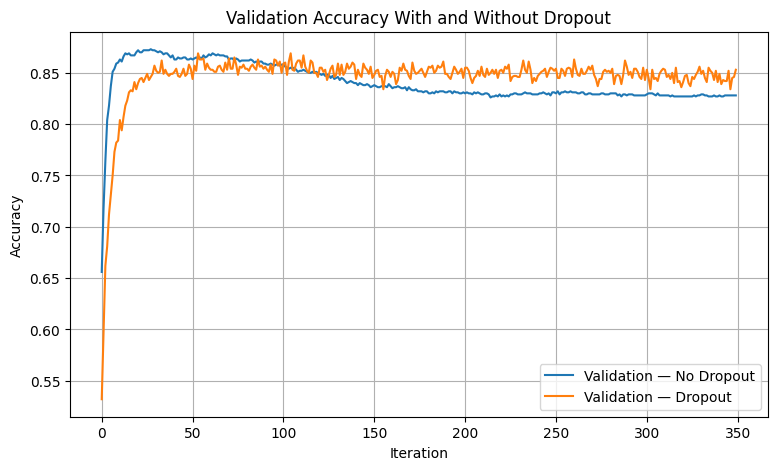

In [12]:
plt.figure(figsize=(9, 5))

plt.plot(val_no_drop, label="Validation — No Dropout")
plt.plot(val_drop, label="Validation — Dropout")

plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy With and Without Dropout")
plt.legend()
plt.grid(True)

plt.savefig("curves_part3.png")
plt.show()

In [13]:
train_acc_no_mask = evaluate_part3(
    X_train, Y_train, W1_drop, W2_drop
)

print(f"Training accuracy with dropout active: {train_drop[-1] * 100:.2f}%")
print(f"Training accuracy with dropout disabled: {train_acc_no_mask * 100:.2f}%")

Training accuracy with dropout active: 88.30%
Training accuracy with dropout disabled: 99.50%


### Part 3 Results

Without dropout, our network reached 99.9% training accuracy, but its final validation accuracy was only 82.8%. With dropout, training accuracy was lower at 88.3%, but validation accuracy improved to 85.3%. However, when we evaluated the dropout model with dropout turned off, its training accuracy was actually 99.5%. This shows that dropout makes training more difficult without preventing the network from learning the data. By randomly disabling neurons during training, it encourages the network to learn more general patterns instead of relying on specific neurons.

## Part 4 — Mini-Batch Training
**Colson**

Mini-batch training processes multiple training examples simultaneously instead of updating the network after every individual image. This allows NumPy to perform larger matrix operations, reducing the overhead associated with individual training steps.

In this section, we compare the execution time and validation accuracy of single-image training against mini-batch training using batches of 100 images.

In [14]:
from part4_batching import train_batched

W1_batch, W2_batch, train_hist4, val_hist4 = train_batched(
    X_train, Y_train, X_val, Y_val, iterations=350
)

print(f"Final training accuracy: {train_hist4[-1] * 100:.2f}%")
print(f"Best validation accuracy: {max(val_hist4) * 100:.2f}%")
print(f"Final validation accuracy: {val_hist4[-1] * 100:.2f}%")

Final training accuracy: 85.70%
Best validation accuracy: 86.40%
Final validation accuracy: 84.20%


In [15]:
from part3_dropout import train_dropout
import time

start = time.perf_counter()
train_dropout(X_train, Y_train, X_val, Y_val, iterations=1)
single_time = time.perf_counter() - start

start = time.perf_counter()
train_batched(X_train, Y_train, X_val, Y_val, iterations=1)
batch_time = time.perf_counter() - start

speedup = single_time / batch_time

print(f"Single-image training: {single_time:.4f} seconds")
print(f"Mini-batch training: {batch_time:.4f} seconds")
print(f"Speed-up factor: {speedup:.2f}x")

Single-image training: 0.1940 seconds
Mini-batch training: 0.0150 seconds
Speed-up factor: 12.96x


### Model Comparison

| Metric | No Dropout | Dropout | Mini-Batch Dropout |
|---|---:|---:|---:|
| Final training accuracy (during training) | 99.90% | 88.30% | 85.70% |
| Training accuracy (dropout disabled) | 99.90% | 99.50% | — |
| Best validation accuracy | 87.30% | 86.90% | 86.40% |
| Final validation accuracy | 82.80% | 85.30% | 84.20% |

**Mini-batch speed-up:** 6.99× compared with single-image training.

## Part 5 — Unit Tests
**Brady**

Unit tests help verify that the implementations behave as expected. They check important properties of the neural networks and help identify errors that might not be obvious from training accuracy alone.

In [16]:
from test_forgetting import main

main()

iter   0 train_acc=0.527 val_acc=0.656
iter   1 train_acc=0.749 val_acc=0.718
iter   2 train_acc=0.802 val_acc=0.764
iter   3 train_acc=0.851 val_acc=0.804
iter   4 train_acc=0.883 val_acc=0.818
iter   5 train_acc=0.898 val_acc=0.837
iter   6 train_acc=0.908 val_acc=0.851
iter   7 train_acc=0.917 val_acc=0.854
iter   8 train_acc=0.923 val_acc=0.859
iter   9 train_acc=0.929 val_acc=0.860
iter  10 train_acc=0.940 val_acc=0.863
iter  11 train_acc=0.944 val_acc=0.861
iter  12 train_acc=0.952 val_acc=0.866
iter  13 train_acc=0.957 val_acc=0.869
iter  14 train_acc=0.957 val_acc=0.868
iter  15 train_acc=0.959 val_acc=0.869
iter  16 train_acc=0.960 val_acc=0.867
iter  17 train_acc=0.963 val_acc=0.867
iter  18 train_acc=0.964 val_acc=0.867
iter  19 train_acc=0.967 val_acc=0.870
iter  20 train_acc=0.972 val_acc=0.872
iter  21 train_acc=0.977 val_acc=0.870
iter  22 train_acc=0.978 val_acc=0.870
iter  23 train_acc=0.980 val_acc=0.872
iter  24 train_acc=0.980 val_acc=0.872
iter  25 train_acc=0.981 

### Part 5 Results

All five unit tests passed. The tests verify that the network demonstrates overfitting, the training functions do not directly reference test data, early stopping restores the best weights, dropout reduces the training-validation accuracy gap, and dropped neurons do not receive weight updates.

These tests help confirm that the implementations behave as expected, beyond simply checking their final accuracy.

## Part 6 — Holocron Reading
**Colson**

### Holocron — Reading

Dropout is weird because it purposefully makes the network do worse during training. Without it, our network reached a 99.9% training accuracy, but its final validation was only 82.8%. When it was enabled, its training accuracy was much lower at 88.3%, but its final validation was higher than without dropout at 85.3%. This is because dropout randomly turns off hidden neurons during training, which forces the network to learn patterns from the data that don't depend on particular combinations of neurons. Instead of essentially memorizing training images, it has to find general patterns that work across various different images.

What is cool though, is that when we turned off dropout and evaluated the network again, its training accuracy reached 99.5%. This proves that the network had still learned the training data well, even though it was more difficult with dropout on.

Korrith's fragment connects this idea to Iron Voice, who supposedly never forgets. His perfect memory seems like an obvious advantage, but it is a weakness if he treats every past experience with equal importance. Like an overfitted network, he risks relying too much on what he remembers and fails to adapt to new situations. This shows that forgetting can end up making learning more effective.